# 03 · Feature engineering

The brief asks for **cycle, rolling mean, rolling slope, operating regime and sensor health** features. Notebook 02 gave concrete reasons for each: readings are noisy (so smooth them), degradation shows up as a trend (so measure slopes), engines start at different health levels (so compare each engine with its own baseline), and the sensors move together (so combine them into one health index).

All feature code lives in `src/features.py` so that notebooks 04 and 05 use exactly the same transformations. This notebook explains and checks each step.

**Three rules we follow:**

1. **Causal features only.** The value at cycle *t* uses cycles 1..*t* of the same engine and nothing after. A test engine that is still running can be processed the same way as a training engine, and future information cannot leak into the past.
2. **Fit on training engines only.** Anything learned from data (regime clusters, normalisation statistics, the PCA health index) is fitted on training engines and then applied unchanged to validation and test engines. In cross-validation it is refitted inside every fold (notebook 04).
3. **No artificial imputation.** Rolling windows use whatever history exists (`min_periods`), so the first cycles of an engine get a valid value from a shorter window instead of a median borrowed from other engines.

In [1]:
import sys
from pathlib import Path

REPO = "https://github.com/WhiteHacker000/Remaining-Useful-Life-Prediction-for-Industrial-Engines.git"

# On Google Colab only the notebook is opened, so clone the repository to get src/ and the data
if "google.colab" in sys.modules and not Path("../src").exists():
    import os, subprocess
    if not Path("/content/rul").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/rul"], check=True)
    os.chdir("/content/rul/notebooks")

# Make the project folder importable (works from notebooks/ locally and on Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from src.config import SENSOR_INFO, USEFUL_SENSORS, SETTING_COLS, RUL_CAP
from src.data import load_cmapss, add_train_rul
from src.features import FeatureBuilder, RegimeScaler
from src.plotting import set_style, save, BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, GREY

set_style()

train, test, rul = load_cmapss("FD001")
train = add_train_rul(train)

## 1. Operating regime and normalisation

### 1.1 Finding regimes

We cluster the three operational settings with k-means after standardising them, and choose *k* with the silhouette score. FD002 is used here because it actually has several regimes; FD001 has only one (notebook 02).

In [2]:
fd002, _, _ = load_cmapss("FD002")
fd002 = add_train_rul(fd002)

X_settings = StandardScaler().fit_transform(fd002[SETTING_COLS])
sample = np.random.default_rng(0).choice(len(X_settings), 5000, replace=False)
sil = {k: silhouette_score(X_settings[sample],
                           KMeans(k, n_init=10, random_state=0).fit_predict(X_settings)[sample])
       for k in range(2, 10)}
pd.Series(sil, name="silhouette").rename_axis("k").round(3).to_frame().T

k,2,3,4,5,6,7,8,9
silhouette,0.614,0.803,0.852,0.933,0.997,0.94,0.902,0.869


The silhouette score peaks clearly at **k = 6**, the six flight conditions of FD002, with almost perfect separation. `RegimeScaler` uses the same procedure (standardise settings, k-means) and then normalises every sensor with the mean and standard deviation **of its own regime**:

$$z_{i,t} = \frac{x_{i,t} - \mu_{r(i,t)}}{\sigma_{r(i,t)}}$$

### 1.2 Why it matters

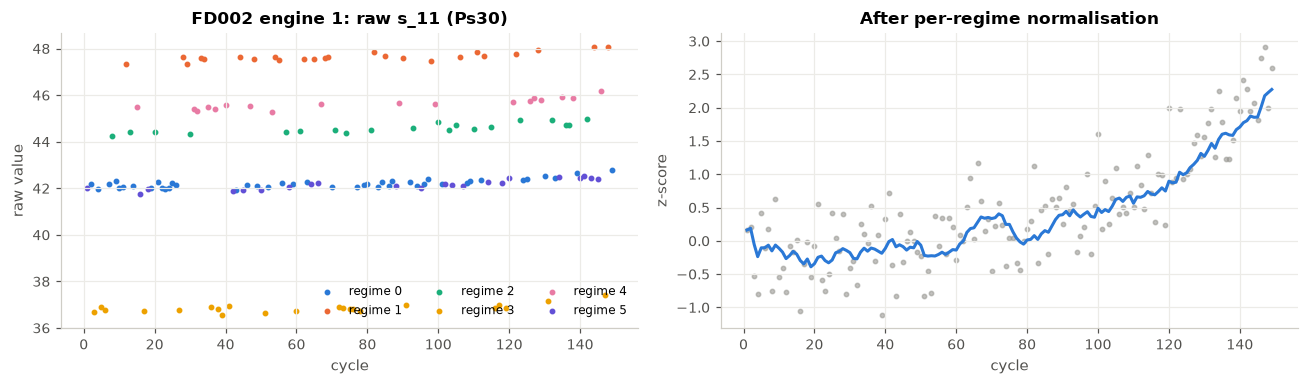

In [3]:
scaler = RegimeScaler(n_regimes=6).fit(fd002)
regimes = scaler.regimes(fd002)
z = scaler.transform(fd002)

unit = 1
mask = fd002["unit"] == unit
palette = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for r in range(6):
    m = mask & (regimes == r)
    axes[0].scatter(fd002.loc[m, "cycle"], fd002.loc[m, "s_11"], s=8, color=palette[r], label=f"regime {r}")
axes[0].set(title=f"FD002 engine {unit}: raw s_11 (Ps30)", xlabel="cycle", ylabel="raw value")
axes[0].legend(ncol=3, fontsize=8)

axes[1].scatter(fd002.loc[mask, "cycle"], z.loc[mask, "s_11"], s=8, color=GREY, alpha=0.6)
axes[1].plot(fd002.loc[mask, "cycle"], z.loc[mask, "s_11"].rolling(10, min_periods=1).mean(), color=BLUE)
axes[1].set(title="After per-regime normalisation", xlabel="cycle", ylabel="z-score")
fig.tight_layout()
save(fig, "03_regime_normalisation")
plt.show()

On the left, the raw reading jumps between six levels depending on the flight condition, and the degradation trend is invisible. After per-regime normalisation (right) the jumps disappear and the upward drift towards failure shows up clearly.

For **FD001** there is one regime, so `RegimeScaler(n_regimes=1)` is simply a z-score fitted on training engines. We keep the general implementation so the same pipeline can later run on FD002/FD004. The regime id is added as a feature only when there is more than one regime; in FD001 it would be a constant column.

## 2. The feature set

`FeatureBuilder` produces seven groups of features. For each of the 14 sensors (with window lengths $w = 10$ and $W = 30$ cycles):

| Group | Features | Formula / idea | Why (from notebook 02) |
|---|---|---|---|
| `sensors` | 14 | regime-normalised reading $z_t$ | the raw information |
| `cycle` | 1 | current cycle $t$ | engines rarely fail very early; age is a prior |
| `rolling` | 28 | mean and std of $z$ over the last $w$ cycles | noise is large relative to the trend; std captures growing instability |
| `slope` | 28 | least-squares slope of $z$ over the last $w$ and $W$ cycles | degradation = a trend, measured directly |
| `baseline_dev` | 14 | rolling mean minus the mean of the engine's first 10 cycles | engines start at different health levels |
| `health` | 3 | first principal component of the 14 $z$ values, its rolling mean and $W$-slope | sensors are collinear and move together |

The rolling slope is the ordinary least-squares coefficient of $z$ on $t$ inside the window:

$$\hat\beta_t = \frac{\sum_{k=t-w+1}^{t}(k - \bar k)(z_k - \bar z)}{\sum_{k=t-w+1}^{t}(k - \bar k)^2}$$

It is computed in vectorised form from rolling means of $t$, $z$, $tz$ and $t^2$ (see `rolling_slope`).

In [4]:
fb = FeatureBuilder(n_regimes=1)       # fitted on all training engines here, for illustration only
features = fb.fit_transform(train)
y = train.loc[features.index, "RUL"].clip(upper=RUL_CAP)

print(f"feature table: {features.shape[0]:,} rows x {len(fb.feature_names)} features")
print(f"missing values: {features[fb.feature_names].isna().sum().sum()}")
pd.Series({g: len(cols) for g, cols in fb.groups.items()}, name="features").to_frame().T

feature table: 20,631 rows x 88 features
missing values: 0


,sensors,cycle,rolling,slope,baseline_dev,health
features,14,1,28,28,14,3


88 features and no missing values. At the start of each engine, rolling means use however many cycles exist so far. Rolling std and slopes wait for half a window of history (5 and 15 cycles) and are 0 until then, because a slope through 3 noisy points is mostly noise. No imputation is needed.

### 2.1 What the features look like

Here are the feature families for one sensor of one engine:

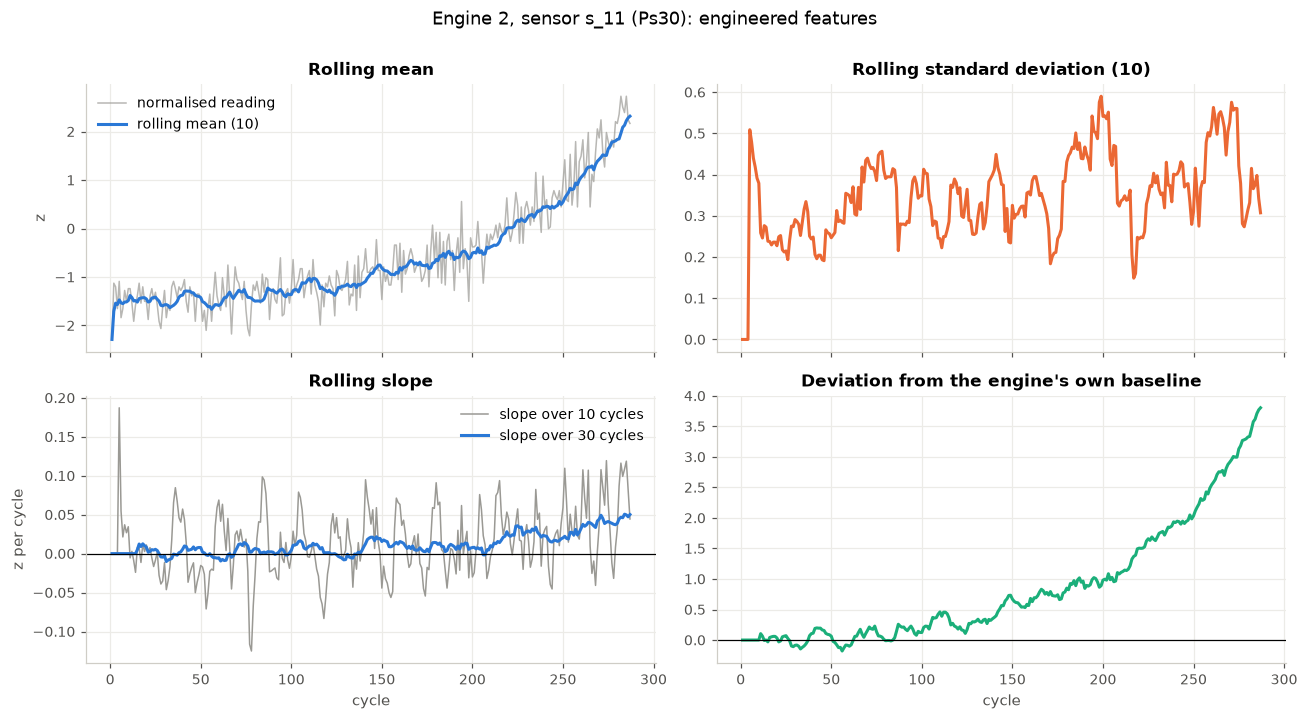

In [5]:
unit, s = 2, "s_11"
e = features[features["unit"] == unit]

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
axes[0, 0].plot(e["cycle"], e[s], color=GREY, lw=1, alpha=0.7, label="normalised reading")
axes[0, 0].plot(e["cycle"], e[f"{s}_mean10"], color=BLUE, label="rolling mean (10)")
axes[0, 0].set(title="Rolling mean", ylabel="z")
axes[0, 0].legend()

axes[0, 1].plot(e["cycle"], e[f"{s}_std10"], color=ORANGE)
axes[0, 1].set(title="Rolling standard deviation (10)")

axes[1, 0].plot(e["cycle"], e[f"{s}_slope10"], color=GREY, lw=1, label="slope over 10 cycles")
axes[1, 0].plot(e["cycle"], e[f"{s}_slope30"], color=BLUE, label="slope over 30 cycles")
axes[1, 0].axhline(0, color="black", lw=0.8)
axes[1, 0].set(title="Rolling slope", xlabel="cycle", ylabel="z per cycle")
axes[1, 0].legend()

axes[1, 1].plot(e["cycle"], e[f"{s}_dev"], color=AQUA)
axes[1, 1].axhline(0, color="black", lw=0.8)
axes[1, 1].set(title="Deviation from the engine's own baseline", xlabel="cycle")

fig.suptitle(f"Engine {unit}, sensor {s} ({SENSOR_INFO[s][0]}): engineered features", y=1.0, fontsize=12)
fig.tight_layout()
save(fig, "03_feature_families")
plt.show()

- The **rolling mean** follows the trend while removing most of the noise.
- The **10-cycle slope** is noisy, close to the raw noise level. The **30-cycle slope** is much steadier and turns clearly positive in the last part of life. That is why we keep both: the short one reacts fast, the long one is reliable.
- The **baseline deviation** starts at 0 for every engine by construction and grows as the engine moves away from its own healthy state. It removes the engine-to-engine offset that a plain reading contains.

### 2.2 The health index

Most sensors respond to the same fault, so their first principal component should work as a single "health" signal. PCA is fitted on training engines only, and its sign is fixed so that the index decreases as the engine ages.

variance explained by the first component: 64.3%


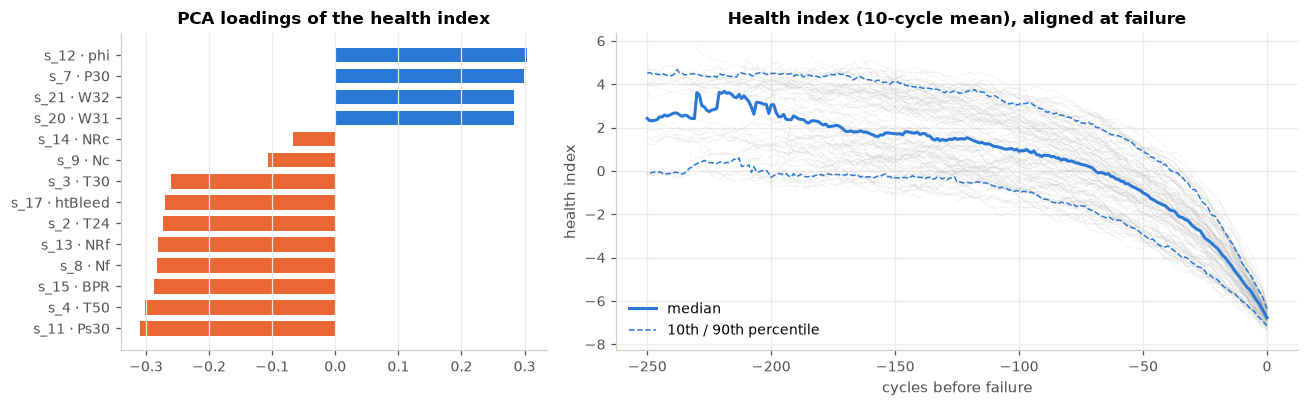

In [6]:
loadings = pd.Series(fb.hi_sign_ * fb.pca_.components_[0], index=USEFUL_SENSORS)
print(f"variance explained by the first component: {fb.pca_.explained_variance_ratio_[0]:.1%}")

hi = features.assign(RUL=train.loc[features.index, "RUL"])
hi = hi[hi["RUL"] <= 250]   # few engines live longer, so percentiles get unstable beyond this
band = hi.groupby("RUL")["health_mean10"].quantile([0.1, 0.5, 0.9]).unstack()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
order = loadings.sort_values().index
axes[0].barh([f"{c} · {SENSOR_INFO[c][0]}" for c in order], loadings[order],
             color=[ORANGE if v < 0 else BLUE for v in loadings[order]], height=0.7)
axes[0].set(title="PCA loadings of the health index")
axes[0].grid(axis="y", visible=False)

for _, g in hi.groupby("unit"):
    axes[1].plot(-g["RUL"], g["health_mean10"], color=GREY, lw=0.5, alpha=0.15)
axes[1].plot(-band.index, band[0.5], color=BLUE, label="median")
axes[1].plot(-band.index, band[0.1], color=BLUE, ls="--", lw=1, label="10th / 90th percentile")
axes[1].plot(-band.index, band[0.9], color=BLUE, ls="--", lw=1)
axes[1].set(title="Health index (10-cycle mean), aligned at failure", xlabel="cycles before failure", ylabel="health index")
axes[1].legend(loc="lower left")
fig.tight_layout()
save(fig, "03_health_index")
plt.show()

The first component explains about 64% of the variance in the 14 normalised sensors. Its loadings make physical sense: temperatures, static pressure `s_11`, bypass ratio and bleed enthalpy enter with one sign, and HPC outlet pressure, fuel-flow ratio and coolant bleeds with the other, matching the directions seen in notebook 02. The core speeds `s_9` and `s_14` get the smallest weights.

Aligned at failure, the index is flat early on and then falls steadily, which makes it a compact summary of engine health. The spread between engines at the same RUL is still large, a reminder that engines degrade at different rates.

## 3. Do the engineered features carry more information?

A first check before any model: rank all 88 features by their absolute Spearman correlation with the capped RUL.

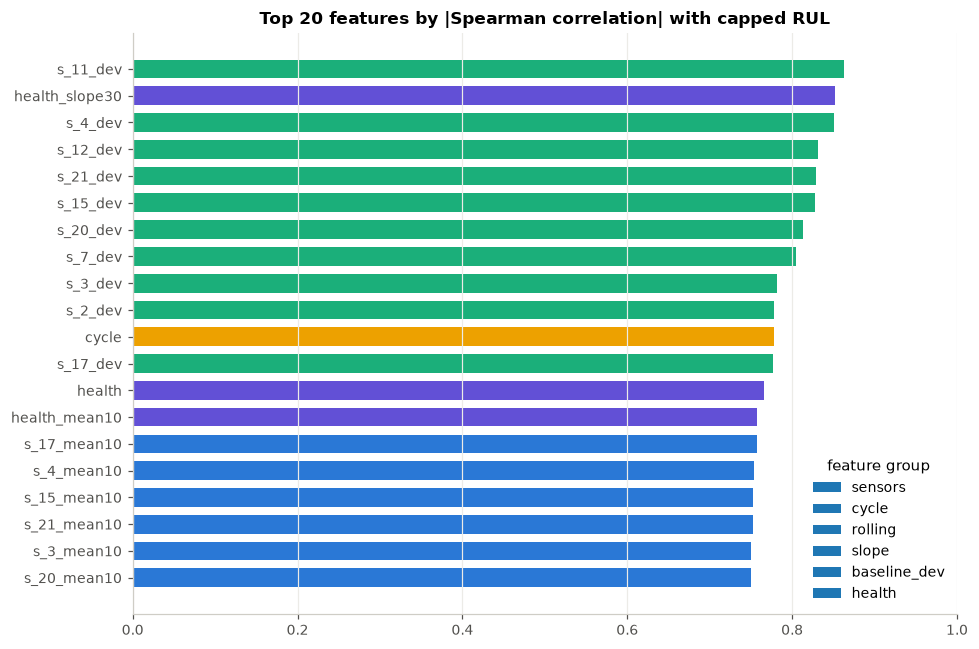

,max,mean
group,,
baseline_dev,0.862,0.724
health,0.852,0.792
cycle,0.778,0.778
rolling,0.757,0.379
sensors,0.720,0.596
slope,0.697,0.374


In [7]:
rho = pd.Series({c: abs(spearmanr(features[c], y)[0]) for c in fb.feature_names})
group_of = {c: g for g, cols in fb.groups.items() for c in cols}
ranking = pd.DataFrame({"|spearman|": rho, "group": pd.Series(group_of)}).sort_values("|spearman|", ascending=False)

group_colors = {"sensors": GREY, "cycle": YELLOW, "rolling": BLUE, "slope": ORANGE,
                "baseline_dev": AQUA, "health": VIOLET}
top = ranking.head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["|spearman|"], color=[group_colors[g] for g in top["group"]], height=0.7)
for g, c in group_colors.items():
    ax.barh([], [], color=c, label=g)
ax.set(title="Top 20 features by |Spearman correlation| with capped RUL", xlim=(0, 1))
ax.legend(loc="lower right", title="feature group")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "03_feature_relevance")
plt.show()

ranking.groupby("group")["|spearman|"].agg(["max", "mean"]).sort_values("max", ascending=False).round(3)

Three groups beat every raw reading. The **baseline deviations** come out on top (best |ρ| about 0.86), followed by the **health index** (about 0.85) and the **cycle** count (about 0.78). The best raw sensor reaches about 0.72. Comparing an engine with its own early-life state removes the engine-to-engine offset, and that is clearly worth a lot. Slopes have lower correlations on their own because they are noisier, but they describe *how fast* an engine is degrading, which a level-based feature cannot. Whether they help in a model is tested properly with an ablation study in notebook 04.

Correlation only looks at one feature at a time, so it cannot show interactions or redundancy. It is a sanity check, not a feature-selection method.

## 4. Leakage check: are the features really causal?

If a feature at cycle *t* used any later cycle, deleting the future would change it. We test this directly: compute the features on full training engines, then again after cutting every engine at a random cycle, and compare the overlapping rows. The FeatureBuilder is the same fitted object, so only the input history changes.

In [8]:
rng = np.random.default_rng(0)
cut = {u: rng.integers(20, n) for u, n in train.groupby("unit")["cycle"].max().items()}
truncated = train[train["cycle"] <= train["unit"].map(cut)]

cols = [c for c in fb.feature_names if c != "cycle"]     # cycle becomes part of the row key
full = fb.transform(train).set_index(["unit", "cycle"])
part = fb.transform(truncated).set_index(["unit", "cycle"])
diff = (full.loc[part.index, cols] - part[cols]).abs().max().max()
print(f"rows compared: {len(part):,}")
print(f"largest difference between full-history and truncated-history features: {diff:.2e}")
assert diff < 1e-9

rows compared: 11,789
largest difference between full-history and truncated-history features: 0.00e+00


The features computed on truncated engines are identical (up to floating-point precision) to those computed on the full histories, so **no feature looks into the future**. The same property is checked automatically in `tests/test_features.py`.

## Summary

- The brief's feature list is covered: **cycle**, **rolling mean** (plus rolling std), **rolling slope** at two horizons, **operating regime** (regime clustering and per-regime normalisation, validated on FD002) and **sensor health** (a PCA health index plus per-engine baseline deviation).
- 88 features, no missing values, no imputation, and a test confirming they are causal.
- Smoothed and health-type features correlate with RUL much more strongly than raw readings.

Notebook 04 measures how much each group actually improves the models.